# Empirical RAG Routing & Uncertainty Dissipation Analysis

This notebook implements end-to-end evaluation of Selective RAG Routing on OpenBookQA across:
1. **Retrieval Modalities & Density (Taxonomy Top Priority)**:
   - **Dense Top-1**: Maximizing premise density and suppressing irrelevant distractor noise.
   - **Dense Top-3**: Standard multi-passage dense semantic retrieval (GTE-Large).
   - **BM25+ Top-3**: Distilled lexical retrieval with optimized length normalization.
   - **BM25 Raw Top-3**: Raw baseline lexical retrieval.
2. **Architecture Families (9 Evaluated Models)**: Qwen 2.5 (1.5B, 3B, 7B, 14B), Llama (3.2-1B, 3.2-3B, Meta-Llama-3-8B), and Phi-3 (Mini 3.8B, Medium 14B).
3. **Epistemic Uncertainty Dissipation**: Tracking $\Delta \mathrm{EU} = \mathrm{EU}_{\mathrm{direct}} - \mathrm{EU}_{\mathrm{rag}}$ across retrieval hits vs. misses.
4. **Selective Budget Routing**: Empirical Pareto frontiers and fixed-budget efficiency metrics.


In [15]:
import os
import sys

# TensorFlow pre-allocation safety flags (Repository Rule: TF_FORCE_GPU_ALLOW_GROWTH)
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['CUDA_MODULE_LOADING'] = 'LAZY'

import glob
import json
import gzip
import pickle
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display, HTML
except ImportError:
    display = print
    HTML = None

try:
    from scipy.ndimage import uniform_filter1d
except ImportError:
    def uniform_filter1d(input, size=3, mode='nearest'):
        return input

# Publication-quality plotting defaults
plt.rcParams['figure.dpi'] = 140
plt.rcParams['font.size'] = 9
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Environment initialized with TF memory growth safety and publication styling.")


Environment initialized with TF memory growth safety and publication styling.


## 1. Deterministic Data Discovery, Retrieval-Prioritized Taxonomy & Dynamic Loading

We load all completed OpenBookQA RAG evaluation runs deterministically from the canonical `experiments/result` directory.
Each run is parsed into a standardized taxonomy with **Retrieval Type given top priority**: `(Retrieval Condition, Architectural Family, Model Scale)`.
This partitions the benchmark into clean condition chunks across all evaluated models (Dense Top-1, Dense Top-3, BM25+ Top-3, Distractor, Oracle), followed by the single BM25 Raw baseline at the end.


In [16]:
import os
import glob
import re
import gzip
import pickle
import numpy as np
import pandas as pd

try:
    from IPython.display import display, HTML
except ImportError:
    display = print
    HTML = None

def extract_model_tag(name):
    bname = os.path.basename(name).replace("_summary.csv", "").replace(".csv", "")
    # 1. Oracle variants -> canonical "oracle_"
    if "oracle" in bname:
        model_part = re.sub(r"^(openbookqa_)?oracle(_top1_rag|_rag|_top1)?_", "", bname)
        return f"oracle_{model_part}"
    # 2. Distractor (Negative Control) variants -> canonical "distractor_"
    elif "distractor" in bname or "random" in bname:
        model_part = re.sub(r"^(openbookqa_)?(distractor_rag_|distractor_|random_distractor_rag_|random_distractor_)", "", bname)
        return f"distractor_{model_part}"
    # 3. Dense Top-1 variants -> canonical "dense_top1_"
    elif "top1" in bname and "oracle" not in bname and "distractor" not in bname:
        model_part = re.sub(r"^(openbookqa_)?(dense_top1_rag_|top1_rag_|dense_top1_)", "", bname)
        return f"dense_top1_{model_part}"
    # 4. Dense Top-3 variants -> canonical "dense_"
    elif "dense" in bname:
        model_part = re.sub(r"^(openbookqa_)?(dense_rag_|dense_)", "", bname)
        return f"dense_{model_part}"
    # 5. BM25+ (Optimized) variants -> canonical "bm25_opt_"
    elif "bm25opt" in bname or "bm25_opt" in bname:
        model_part = re.sub(r"^(openbookqa_)?(bm25opt_rag_|bm25_opt_rag_|bm25opt_|bm25_opt_)", "", bname)
        return f"bm25_opt_{model_part}"
    # 6. BM25 Raw variants -> canonical "bm25_raw_"
    elif "bm25_raw" in bname or "bm25raw" in bname or ("bm25" in bname and "opt" not in bname) or "openbookqa_rag" in bname or bname.startswith("bm25_"):
        model_part = re.sub(r"^(openbookqa_)?(bm25_raw_|bm25raw_|bm25_rag_|bm25_|rag_)", "", bname)
        return f"bm25_raw_{model_part}"
    return bname

def parse_run_tag(tag):
    """
    Parse run identifiers into standardized architectural family, model scale, and retrieval condition.
    Retrieval condition has top priority for taxonomy ordering.
    """
    t = str(tag).strip()
    
    # 1. Condition extraction (Top Priority)
    if "oracle" in t:
        cond = "Oracle (Gold Fact)"
        cond_order = 0
        cond_type = "oracle"
        model_part = re.sub(r"^.*?(oracle_top1_rag_|oracle_rag_|oracle_)", "", t)
    elif "distractor" in t or "random" in t:
        cond = "Distractor (Negative Control)"
        cond_order = 4
        cond_type = "distractor"
        model_part = re.sub(r"^.*?(distractor_rag_|distractor_|random_distractor_rag_|random_distractor_)", "", t)
    elif "top1" in t and "oracle" not in t and "distractor" not in t:
        cond = "Dense (Top-1)"
        cond_order = 1
        cond_type = "dense_top1"
        model_part = re.sub(r"^.*?(dense_top1_rag_|top1_rag_|dense_top1_)", "", t)
    elif "dense" in t:
        cond = "Dense (Top-3)"
        cond_order = 2
        cond_type = "dense"
        model_part = re.sub(r"^.*?(dense_rag_|dense_)", "", t)
    elif "bm25opt" in t or "bm25_opt" in t:
        cond = "BM25+ (Top-3)"
        cond_order = 3
        cond_type = "bm25_opt"
        model_part = re.sub(r"^.*?(bm25opt_rag_|bm25_opt_|bm25opt_)", "", t)
    elif "bm25_raw" in t or "bm25raw" in t or ("bm25" in t and "opt" not in t) or "openbookqa_rag" in t:
        cond = "BM25 Raw (Top-3)"
        cond_order = 5
        cond_type = "bm25_raw"
        model_part = re.sub(r"^.*?(bm25_raw_|openbookqa_rag_|bm25raw_|bm25_)", "", t)
    else:
        cond = "Other"
        cond_order = 6
        cond_type = "other"
        model_part = t
        
    # 2. Architectural family and scale extraction
    m_lower = model_part.lower()
    if "qwen" in m_lower:
        family = "Qwen 2.5"
        family_order = 1
        if "1.5b" in m_lower:
            model_name = "Qwen2.5-1.5B"
            size_order = 1
        elif "3b" in m_lower:
            model_name = "Qwen2.5-3B"
            size_order = 2
        elif "7b" in m_lower:
            model_name = "Qwen2.5-7B"
            size_order = 3
        elif "14b" in m_lower:
            model_name = "Qwen2.5-14B"
            size_order = 4
        else:
            model_name = model_part
            size_order = 5
    elif "llama" in m_lower:
        family = "Llama"
        family_order = 2
        if "3.2-1b" in m_lower or "1b" in m_lower:
            model_name = "Llama-3.2-1B"
            size_order = 1
        elif "3.2-3b" in m_lower or "3b" in m_lower:
            model_name = "Llama-3.2-3B"
            size_order = 2
        elif "meta-llama-3-8b" in m_lower or "3-8b" in m_lower or "8b" in m_lower:
            model_name = "Meta-Llama-3-8B"
            size_order = 3
        else:
            model_name = model_part
            size_order = 4
    elif "phi" in m_lower:
        family = "Phi-3"
        family_order = 3
        if "mini" in m_lower or "3.8b" in m_lower:
            model_name = "Phi-3-Mini-4k (3.8B)"
            size_order = 1
        elif "medium" in m_lower or "14b" in m_lower:
            model_name = "Phi-3-Medium-4k (14B)"
            size_order = 2
        else:
            model_name = model_part
            size_order = 3
    else:
        family = "Other"
        family_order = 4
        model_name = model_part
        size_order = 99
        
    return {
        'run_id': t,
        'family': family,
        'model_name': model_name,
        'condition': cond,
        'cond_type': cond_type,
        'sort_key': (cond_order, family_order, size_order)
    }

notebook_dir = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()

def discover_rag_runs():
    found_runs = {}
    
    # Deterministic result directory resolution (Workspace Rule)
    search_bases = [
        notebook_dir,
        os.path.join(notebook_dir, "sdlg"),
        "/notebooks",
        "/notebooks/sdlg",
        "/workspace",
        "/workspace/sdlg",
    ]
    possible_result_dirs = []
    # 1. Canonical experiment result directories (Highest Priority)
    for base in search_bases:
        possible_result_dirs.append(os.path.join(base, "src", "experiments", "result"))
        possible_result_dirs.append(os.path.join(base, "experiments", "result"))
    for base in search_bases:
        possible_result_dirs.append(os.path.join(base, "result"))
        
    # 2. Local transfer fallbacks
    for base in search_bases:
        possible_result_dirs.append(os.path.join(base, "src", "experiments"))
        possible_result_dirs.append(os.path.join(base, "experiments"))
    for base in search_bases:
        possible_result_dirs.append(os.path.join(base, "src"))

    valid_dirs = []
    for d in possible_result_dirs:
        norm_d = os.path.normpath(d)
        if os.path.isdir(norm_d) and norm_d not in valid_dirs:
            entries = [e for e in os.listdir(norm_d) if e.startswith("openbookqa_") or e.startswith("bm25_") or e.startswith("dense_") or e.startswith("oracle_") or e.startswith("distractor_")]
            if entries:
                valid_dirs.append(norm_d)
                
    if not valid_dirs:
        print("Warning: No valid experiments/result directory containing openbookqa runs found.")
        return found_runs
        
    print(f"Loading OpenBookQA RAG runs deterministically from: {', '.join(valid_dirs)}")
    
    seen_model_conds = set()
    
    # Iterate across candidate directories in priority order
    for d in valid_dirs:
        # Pass 1: Prioritize completed run directories with full pickles / summary CSV
        for entry in sorted(os.listdir(d)):
            if not (entry.startswith("openbookqa_") or entry.startswith("bm25_") or entry.startswith("dense_") or entry.startswith("oracle_") or entry.startswith("distractor_")):
                continue
            full_path = os.path.join(d, entry)
            if os.path.isdir(full_path):
                csv_path = os.path.join(full_path, "rag_evaluation_summary.csv")
                pickles = glob.glob(os.path.join(full_path, "results_dict_*.pkl*"))
                if os.path.exists(csv_path) or pickles:
                    tag = extract_model_tag(entry)
                    meta = parse_run_tag(tag)
                    key = (meta['cond_type'], meta['model_name'])
                    if key not in seen_model_conds:
                        seen_model_conds.add(key)
                        found_runs[tag] = full_path

        # Pass 2: Fallback to standalone summary CSVs for models not found in subdirectories
        for entry in sorted(os.listdir(d)):
            if not (entry.startswith("openbookqa_") or entry.startswith("bm25_") or entry.startswith("dense_") or entry.startswith("oracle_") or entry.startswith("distractor_")):
                continue
            full_path = os.path.join(d, entry)
            if os.path.isfile(full_path) and entry.endswith(".csv"):
                tag = extract_model_tag(entry)
                meta = parse_run_tag(tag)
                key = (meta['cond_type'], meta['model_name'])
                if key not in seen_model_conds:
                    seen_model_conds.add(key)
                    found_runs[tag] = full_path
                    
    return found_runs

def load_rag_data(path):
    df = pd.DataFrame()
    
    # 1. Direct CSV file
    if os.path.isfile(path) and path.endswith('.csv'):
        try:
            df = pd.read_csv(path)
        except Exception:
            return pd.DataFrame()
            
    # 2. Directory containing rag_evaluation_summary.csv
    elif os.path.isdir(path):
        csv_path = os.path.join(path, "rag_evaluation_summary.csv")
        if os.path.exists(csv_path):
            try:
                df = pd.read_csv(csv_path)
            except Exception:
                df = pd.DataFrame()
                
        # Fallback to pickles in directory
        if len(df) == 0:
            pickles = sorted(glob.glob(os.path.join(path, "results_dict_*.pkl*")))
            records = []
            for p_file in pickles:
                open_fn = gzip.open if p_file.endswith('.gz') else open
                try:
                    with open_fn(p_file, 'rb') as fp:
                        item = pickle.load(fp)
                        d_corr = item.get('direct', {}).get('is_correct', 0)
                        r_corr = item.get('rag', {}).get('is_correct', 0)
                        tot_l = item.get('direct', {}).get('layer_metrics', {}).get('total_layers', 28)
                        ka_idx = min(2, tot_l - 1)
                        ke_idx = min(27, tot_l - 1)
                        records.append({
                            'idx': item.get('idx', 0),
                            'retriever_hit_at_k': item.get('retriever_hit_at_k', 0),
                            'is_correct_direct': d_corr,
                            'is_correct_rag': r_corr,
                            'delta_correct': r_corr - d_corr,
                            'eu_pre': item.get('direct', {}).get('layer_metrics', {}).get('entropy_final', 0.0) - item.get('direct', {}).get('layer_metrics', {}).get(f'entropy_mixture_top_{ke_idx}', 0.0),
                            'au_pre': item.get('direct', {}).get('layer_metrics', {}).get(f'entropy_mixture_top_{ka_idx}', 0.0),
                            'eu_post': item.get('rag', {}).get('layer_metrics', {}).get('entropy_final', 0.0) - item.get('rag', {}).get('layer_metrics', {}).get(f'entropy_mixture_top_{ke_idx}', 0.0),
                            'au_post': item.get('rag', {}).get('layer_metrics', {}).get(f'entropy_mixture_top_{ka_idx}', 0.0),
                            'h_final_pre': item.get('direct', {}).get('layer_metrics', {}).get('entropy_final', 0.0)
                        })
                except Exception:
                    continue
            if records:
                df = pd.DataFrame(records)

    if len(df) == 0:
        return df

    # Standardize column headers (strip whitespace and BOM)
    df.columns = [str(c).strip().lstrip('\ufeff') for c in df.columns]

    # Normalize Direct Correctness column
    if 'is_correct_direct' not in df.columns:
        if 'direct_is_correct' in df.columns:
            df['is_correct_direct'] = df['direct_is_correct']
        elif 'direct_correct' in df.columns:
            df['is_correct_direct'] = df['direct_correct']
        elif 'bleurt_direct' in df.columns:
            df['is_correct_direct'] = (df['bleurt_direct'] >= 0.0).astype(int)
        elif 'is_correct' in df.columns and 'is_correct_rag' in df.columns:
            df['is_correct_direct'] = df['is_correct']

    # Normalize RAG Correctness column
    if 'is_correct_rag' not in df.columns:
        if 'rag_is_correct' in df.columns:
            df['is_correct_rag'] = df['rag_is_correct']
        elif 'rag_correct' in df.columns:
            df['is_correct_rag'] = df['rag_correct']
        elif 'bleurt_rag' in df.columns:
            df['is_correct_rag'] = (df['bleurt_rag'] >= 0.0).astype(int)

    # Validate essential sample correctness columns
    if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns:
        return pd.DataFrame()

    if 'delta_eu' not in df.columns and 'eu_pre' in df.columns and 'eu_post' in df.columns:
        df['delta_eu'] = df['eu_pre'] - df['eu_post']
    if 'delta_au' not in df.columns and 'au_pre' in df.columns and 'au_post' in df.columns:
        df['delta_au'] = df['au_pre'] - df['au_post']
    if 'delta_correct' not in df.columns:
        df['delta_correct'] = df['is_correct_rag'] - df['is_correct_direct']
    if 'h_final_pre' not in df.columns and 'entropy_final' in df.columns:
        df['h_final_pre'] = df['entropy_final']
    elif 'h_final_pre' not in df.columns and 'eu_pre' in df.columns:
        df['h_final_pre'] = df['eu_pre']

    return df

def compute_pareto_curve(metric_scores, y_direct, y_rag, n_points=35, smooth_window=3):
    sorted_indices = np.argsort(-metric_scores)
    budgets = np.linspace(0.0, 1.0, n_points)
    raw_accuracies = []
    n_total = len(y_direct)
    
    for b in budgets:
        k = int(round(b * n_total))
        routed = np.copy(y_direct)
        if k > 0:
            routed[sorted_indices[:k]] = y_rag[sorted_indices[:k]]
        raw_accuracies.append(float(np.mean(routed)))
        
    raw_arr = np.array(raw_accuracies)
    if smooth_window > 1:
        try:
            from scipy.ndimage import uniform_filter1d
            smoothed = uniform_filter1d(raw_arr, size=smooth_window, mode='nearest')
            smoothed[0] = raw_arr[0]
            smoothed[-1] = raw_arr[-1]
        except Exception:
            smoothed = raw_arr
    else:
        smoothed = raw_arr
        
    return budgets, smoothed

def display_table_chunks(df, condition_col='Condition', title=None):
    """
    Display benchmark table partitioned into clean condition chunks with horizontal bars between them.
    """
    if len(df) == 0:
        return
        
    if condition_col not in df.columns:
        display(df)
        return
        
    cond_order_map = {
        'Oracle (Gold Fact)': 0,
        'Dense (Top-1)': 1,
        'Dense (Top-3)': 2,
        'BM25+ (Top-3)': 3,
        'Distractor (Negative Control)': 4,
        'Random Distractor (Top-1)': 4,
        'Random Distractor': 4,
        'Distractor': 4,
        'BM25 Raw (Top-3)': 5,
    }
    
    unique_conds = []
    for c in df[condition_col].unique():
        if c not in unique_conds:
            unique_conds.append(c)
    unique_conds.sort(key=lambda c: cond_order_map.get(c, 99))
    
    if title:
        try:
            from IPython.display import display, HTML
            display(HTML(f"<h3 style='margin: 18px 0 8px 0; color: #1a202c; border-bottom: 2px solid #2b6cb0; padding-bottom: 4px;'>{title}</h3>"))
        except Exception:
            print(f"\n{'='*30} {title} {'='*30}")
            
    for i, cond in enumerate(unique_conds):
        chunk = df[df[condition_col] == cond].copy()
        if len(chunk) == 0:
            continue
            
        try:
            from IPython.display import display, HTML
            display(HTML(f"<h4 style='margin: 14px 0 6px 0; color: #2c5282; font-family: sans-serif;'>▶ {cond} <span style='font-size: 12px; color: #718096; font-weight: normal;'>({len(chunk)} models)</span></h4>"))
            display(chunk)
            if i < len(unique_conds) - 1:
                display(HTML("<hr style='border: none; border-top: 2px solid #cbd5e0; margin: 18px 0 14px 0;'>"))
        except Exception:
            print(f"\n▶ [{cond.upper()}] ({len(chunk)} models)")
            display(chunk)
            if i < len(unique_conds) - 1:
                print("-" * 90)

available_runs = discover_rag_runs()
sorted_runs = sorted(available_runs.keys(), key=lambda k: parse_run_tag(k)['sort_key'])
print(f"Discovered {len(available_runs)} OpenBookQA RAG runs categorized hierarchically (Retrieval Type Priority):\n")

current_cond = None
for r in sorted_runs:
    m = parse_run_tag(r)
    if m['condition'] != current_cond:
        if current_cond is not None:
            print("-" * 75)
        current_cond = m['condition']
        print(f"=== {current_cond.upper()} ===")
    print(f"  • [{m['family']}] {m['model_name']:<22} | {m['condition']:<16} ({r})")


Loading OpenBookQA RAG runs deterministically from: /notebooks/sdlg/src/experiments/result
Discovered 29 OpenBookQA RAG runs categorized hierarchically (Retrieval Type Priority):

=== ORACLE (GOLD FACT) ===
  • [Qwen 2.5] Qwen2.5-1.5B           | Oracle (Gold Fact) (oracle_qwen2.5-1.5b)
  • [Qwen 2.5] Qwen2.5-3B             | Oracle (Gold Fact) (oracle_qwen2.5-3b)
  • [Qwen 2.5] Qwen2.5-7B             | Oracle (Gold Fact) (oracle_qwen2.5-7b)
  • [Qwen 2.5] Qwen2.5-14B            | Oracle (Gold Fact) (oracle_qwen2.5-14b)
  • [Llama] Llama-3.2-3B           | Oracle (Gold Fact) (oracle_llama-3.2-3b)
  • [Llama] Meta-Llama-3-8B        | Oracle (Gold Fact) (oracle_meta-llama-3-8b)
  • [Phi-3] Phi-3-Medium-4k (14B)  | Oracle (Gold Fact) (oracle_phi-3-medium-4k)
---------------------------------------------------------------------------
=== DENSE (TOP-1) ===
  • [Qwen 2.5] Qwen2.5-1.5B           | Dense (Top-1)    (dense_top1_qwen2.5-1.5b)
  • [Qwen 2.5] Qwen2.5-3B             | Dense (Top-1)

## 2. Correctness Transitions & Diagnostic Distribution

We evaluate sample-level correctness state transitions across the 3 retrieval condition chunks:
- **Recovered (0 $\rightarrow$ 1)**: Retrieval corrected an initially failing direct answer.
- **Retained (1 $\rightarrow$ 1)**: Correct direct answer maintained under retrieval augmentation.
- **Distracted (1 $\rightarrow$ 0)**: In-context distractor noise corrupted an initially correct answer.
- **Persistent (0 $\rightarrow$ 0)**: Unresolved knowledge deficit.


In [17]:
# Section 2: Consolidated Correctness Transitions & Diagnostic Table
if 'dfs' not in locals() or not dfs:
    dfs = {}

sorted_runs = sorted(available_runs.keys(), key=lambda k: parse_run_tag(k)['sort_key'])

transition_records = []
seen_transitions = set()

for m_name in sorted_runs:
    meta = parse_run_tag(m_name)
    model_key = (meta['condition'], meta['model_name'])
    if model_key in seen_transitions:
        continue
        
    path = available_runs[m_name]
    df = load_rag_data(path)
    if len(df) == 0 or 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns:
        continue
    dfs[m_name] = df
    seen_transitions.add(model_key)
    
    n_total = len(df)
    base_acc = df['is_correct_direct'].mean() * 100
    rag_acc = df['is_correct_rag'].mean() * 100
    net_delta = rag_acc - base_acc
    hit_rate = (df['retriever_hit_at_k'].mean() * 100) if 'retriever_hit_at_k' in df.columns else np.nan
    
    rec = int(np.sum((df['is_correct_direct'] == 0) & (df['is_correct_rag'] == 1)))
    ret = int(np.sum((df['is_correct_direct'] == 1) & (df['is_correct_rag'] == 1)))
    dis = int(np.sum((df['is_correct_direct'] == 1) & (df['is_correct_rag'] == 0)))
    per = int(np.sum((df['is_correct_direct'] == 0) & (df['is_correct_rag'] == 0)))
    
    transition_records.append({
        'Condition': meta['condition'],
        'Family': meta['family'],
        'Model': meta['model_name'],
        'N': n_total,
        'Hit@K': f"{hit_rate:.1f}%" if not np.isnan(hit_rate) else "-",
        'Direct Acc': f"{base_acc:.2f}%",
        'Post-RAG Acc': f"{rag_acc:.2f}%",
        'Net Δ': f"{net_delta:+.2f}%",
        'Recovered (0->1)': f"{rec} ({rec/n_total*100:.1f}%)",
        'Retained (1->1)': f"{ret} ({ret/n_total*100:.1f}%)",
        'Distracted (1->0)': f"{dis} ({dis/n_total*100:.1f}%)",
        'Persistent (0->0)': f"{per} ({per/n_total*100:.1f}%)"
    })

transition_df = pd.DataFrame(transition_records)
display_table_chunks(transition_df, title="Correctness State Transitions")


,Condition,Family,Model,N,Hit@K,Direct Acc,Post-RAG Acc,Net Δ,Recovered (0->1),Retained (1->1),Distracted (1->0),Persistent (0->0)
0,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-1.5B,500,100.0%,37.20%,45.80%,+8.60%,108 (21.6%),121 (24.2%),65 (13.0%),206 (41.2%)
1,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-3B,500,100.0%,27.40%,24.40%,-3.00%,59 (11.8%),63 (12.6%),74 (14.8%),304 (60.8%)
2,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-7B,500,100.0%,40.20%,46.00%,+5.80%,85 (17.0%),145 (29.0%),56 (11.2%),214 (42.8%)
3,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-14B,500,100.0%,29.40%,39.00%,+9.60%,75 (15.0%),120 (24.0%),27 (5.4%),278 (55.6%)
4,Oracle (Gold Fact),Llama,Llama-3.2-3B,500,100.0%,23.40%,37.40%,+14.00%,97 (19.4%),90 (18.0%),27 (5.4%),286 (57.2%)
5,Oracle (Gold Fact),Llama,Meta-Llama-3-8B,500,100.0%,23.00%,36.20%,+13.20%,94 (18.8%),87 (17.4%),28 (5.6%),291 (58.2%)
6,Oracle (Gold Fact),Phi-3,Phi-3-Medium-4k (14B),500,100.0%,20.40%,24.40%,+4.00%,67 (13.4%),55 (11.0%),47 (9.4%),331 (66.2%)


,Condition,Family,Model,N,Hit@K,Direct Acc,Post-RAG Acc,Net Δ,Recovered (0->1),Retained (1->1),Distracted (1->0),Persistent (0->0)
7,Dense (Top-1),Qwen 2.5,Qwen2.5-1.5B,500,52.0%,37.20%,38.40%,+1.20%,79 (15.8%),113 (22.6%),73 (14.6%),235 (47.0%)
8,Dense (Top-1),Qwen 2.5,Qwen2.5-3B,500,52.0%,27.60%,22.20%,-5.40%,51 (10.2%),60 (12.0%),78 (15.6%),311 (62.2%)
9,Dense (Top-1),Qwen 2.5,Qwen2.5-7B,500,52.0%,40.20%,41.00%,+0.80%,67 (13.4%),138 (27.6%),63 (12.6%),232 (46.4%)
10,Dense (Top-1),Qwen 2.5,Qwen2.5-14B,500,52.0%,29.40%,36.40%,+7.00%,67 (13.4%),115 (23.0%),32 (6.4%),286 (57.2%)
11,Dense (Top-1),Llama,Llama-3.2-3B,500,52.0%,23.00%,34.20%,+11.20%,84 (16.8%),87 (17.4%),28 (5.6%),301 (60.2%)
12,Dense (Top-1),Llama,Meta-Llama-3-8B,500,52.0%,23.00%,31.20%,+8.20%,74 (14.8%),82 (16.4%),33 (6.6%),311 (62.2%)
13,Dense (Top-1),Phi-3,Phi-3-Medium-4k (14B),500,52.0%,20.40%,24.00%,+3.60%,63 (12.6%),57 (11.4%),45 (9.0%),335 (67.0%)


,Condition,Family,Model,N,Hit@K,Direct Acc,Post-RAG Acc,Net Δ,Recovered (0->1),Retained (1->1),Distracted (1->0),Persistent (0->0)
14,Dense (Top-3),Qwen 2.5,Qwen2.5-1.5B,500,71.8%,37.20%,35.20%,-2.00%,74 (14.8%),102 (20.4%),84 (16.8%),240 (48.0%)
15,Dense (Top-3),Qwen 2.5,Qwen2.5-3B,500,71.8%,27.60%,20.40%,-7.20%,48 (9.6%),54 (10.8%),84 (16.8%),314 (62.8%)
16,Dense (Top-3),Qwen 2.5,Qwen2.5-7B,500,71.8%,40.20%,40.60%,+0.40%,75 (15.0%),128 (25.6%),73 (14.6%),224 (44.8%)
17,Dense (Top-3),Qwen 2.5,Qwen2.5-14B,500,71.8%,29.40%,35.80%,+6.40%,73 (14.6%),106 (21.2%),41 (8.2%),280 (56.0%)
18,Dense (Top-3),Llama,Llama-3.2-3B,500,71.8%,24.00%,32.80%,+8.80%,80 (16.0%),84 (16.8%),36 (7.2%),300 (60.0%)
19,Dense (Top-3),Llama,Meta-Llama-3-8B,500,71.8%,23.00%,31.40%,+8.40%,83 (16.6%),74 (14.8%),41 (8.2%),302 (60.4%)
20,Dense (Top-3),Phi-3,Phi-3-Medium-4k (14B),500,71.8%,20.40%,22.80%,+2.40%,59 (11.8%),55 (11.0%),47 (9.4%),339 (67.8%)


,Condition,Family,Model,N,Hit@K,Direct Acc,Post-RAG Acc,Net Δ,Recovered (0->1),Retained (1->1),Distracted (1->0),Persistent (0->0)
21,BM25+ (Top-3),Qwen 2.5,Qwen2.5-1.5B,500,57.4%,37.20%,34.60%,-2.60%,71 (14.2%),102 (20.4%),84 (16.8%),243 (48.6%)
22,BM25+ (Top-3),Qwen 2.5,Qwen2.5-3B,500,57.4%,27.60%,20.40%,-7.20%,54 (10.8%),48 (9.6%),90 (18.0%),308 (61.6%)
23,BM25+ (Top-3),Qwen 2.5,Qwen2.5-7B,500,57.4%,40.20%,40.00%,-0.20%,73 (14.6%),127 (25.4%),74 (14.8%),226 (45.2%)
24,BM25+ (Top-3),Qwen 2.5,Qwen2.5-14B,500,57.4%,29.40%,36.20%,+6.80%,71 (14.2%),110 (22.0%),37 (7.4%),282 (56.4%)
25,BM25+ (Top-3),Llama,Llama-3.2-3B,500,57.4%,23.60%,33.80%,+10.20%,82 (16.4%),87 (17.4%),31 (6.2%),300 (60.0%)
26,BM25+ (Top-3),Llama,Meta-Llama-3-8B,500,57.4%,23.00%,27.80%,+4.80%,64 (12.8%),75 (15.0%),40 (8.0%),321 (64.2%)
27,BM25+ (Top-3),Phi-3,Phi-3-Medium-4k (14B),500,57.4%,20.40%,21.80%,+1.40%,52 (10.4%),57 (11.4%),45 (9.0%),346 (69.2%)


,Condition,Family,Model,N,Hit@K,Direct Acc,Post-RAG Acc,Net Δ,Recovered (0->1),Retained (1->1),Distracted (1->0),Persistent (0->0)
28,BM25 Raw (Top-3),Qwen 2.5,Qwen2.5-1.5B,500,39.0%,37.20%,32.00%,-5.20%,61 (12.2%),99 (19.8%),87 (17.4%),253 (50.6%)


## 3. Stratified Epistemic Dissipation Analysis (Hits vs. Misses)

We evaluate how epistemic uncertainty dissipates upon external context integration:
$$\Delta \mathrm{EU} = \mathrm{EU}_{\mathrm{direct}} - \mathrm{EU}_{\mathrm{rag}}$$
- **Retriever Hits (Green)**: True premise injected $\rightarrow$ Epistemic uncertainty dissipates ($\Delta \mathrm{EU} > 0$).
- **Retriever Misses (Crimson)**: Irrelevant distractor noise injected $\rightarrow$ Epistemic uncertainty increases or remains stagnant ($\Delta \mathrm{EU} \le 0$).
- **Discrimination Margin**: $\mu(\Delta \mathrm{EU}_{\mathrm{Hit}}) - \mu(\Delta \mathrm{EU}_{\mathrm{Miss}})$.


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

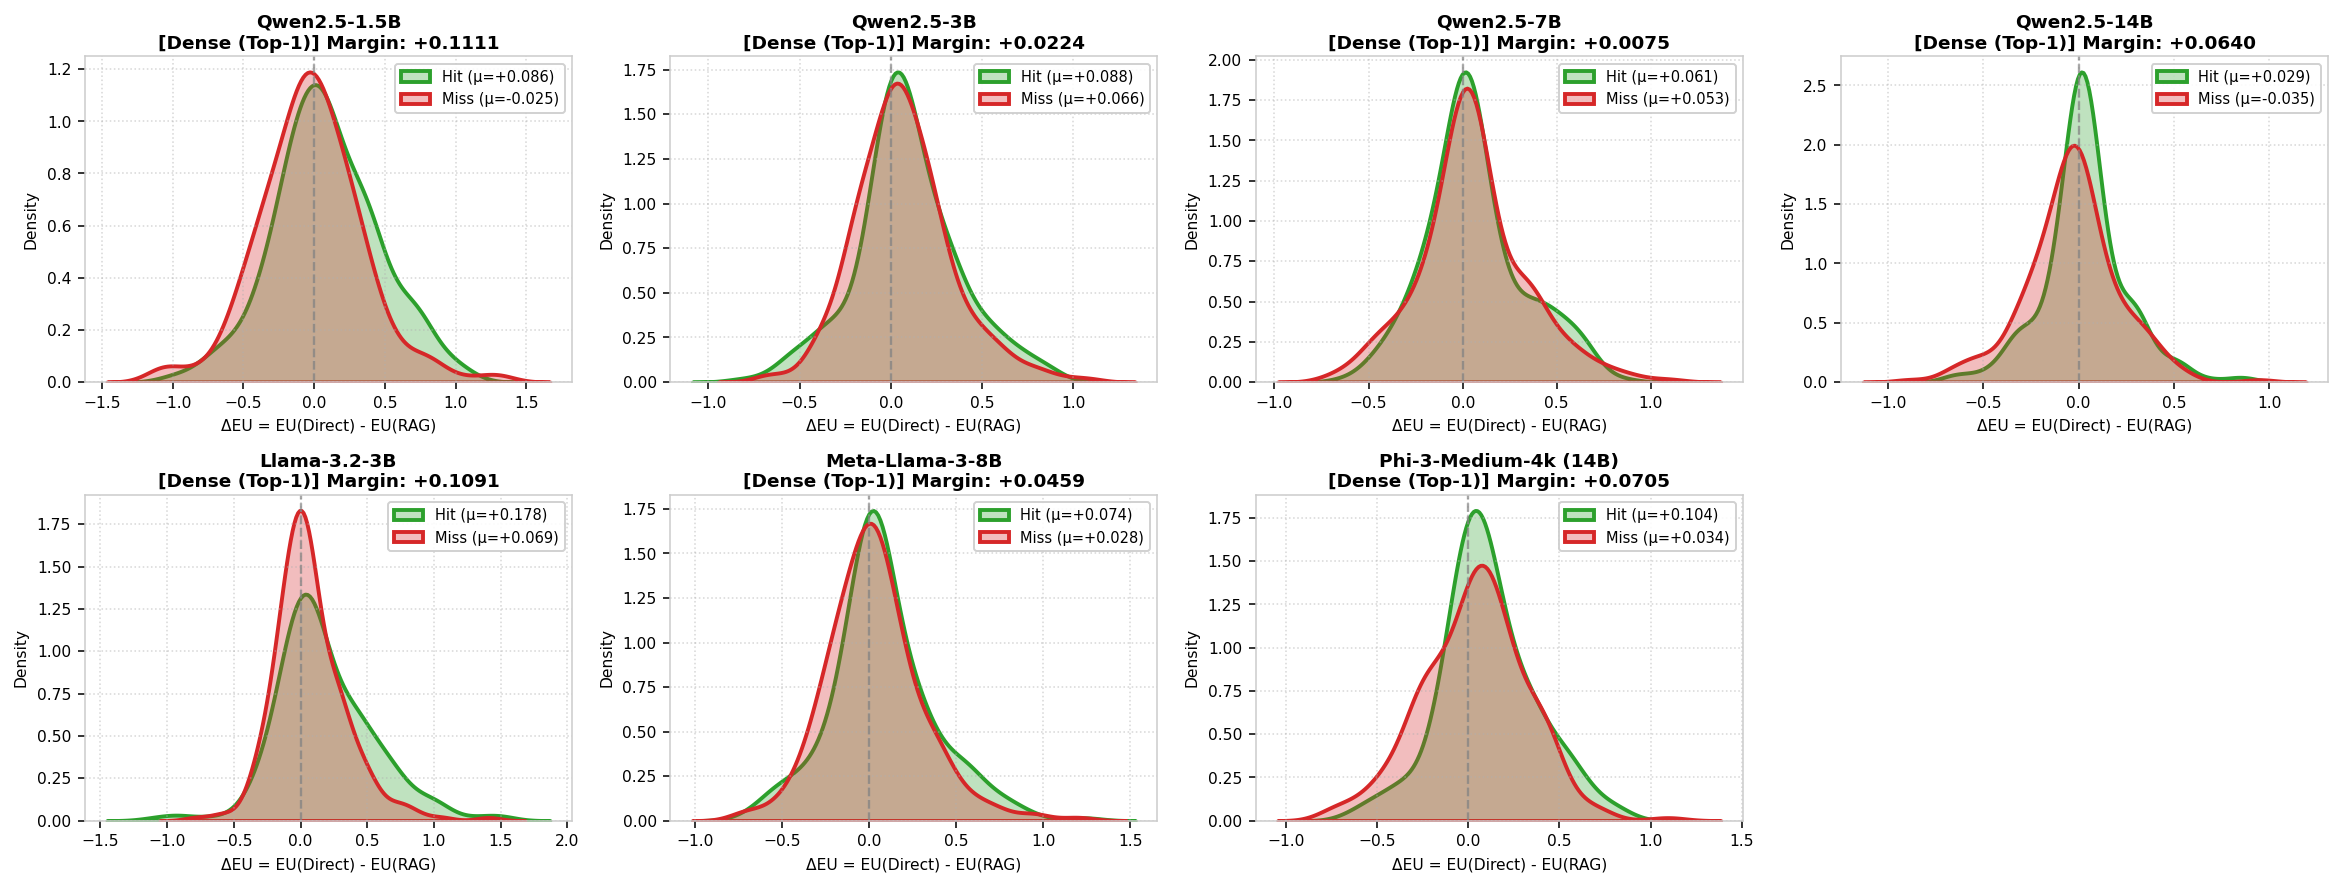

,Condition,Family,Model,Hit Samples (N),Miss Samples (N),Mean ΔEU (Hits),Mean ΔEU (Misses),Discrimination Margin
0,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-1.5B,500,0,+0.0680,+0.0000,+0.0680
1,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-1.5B,500,0,+0.0680,+0.0000,+0.0680
2,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-1.5B,500,0,+0.0680,+0.0000,+0.0680
3,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-3B,500,0,+0.0851,+0.0000,+0.0851
4,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-3B,500,0,+0.0851,+0.0000,+0.0851
5,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-3B,500,0,+0.0851,+0.0000,+0.0851
6,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-7B,500,0,+0.0451,+0.0000,+0.0451
7,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-7B,500,0,+0.0451,+0.0000,+0.0451
8,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-7B,500,0,+0.0451,+0.0000,+0.0451
9,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-14B,500,0,+0.0213,+0.0000,+0.0213


,Condition,Family,Model,Hit Samples (N),Miss Samples (N),Mean ΔEU (Hits),Mean ΔEU (Misses),Discrimination Margin
21,Dense (Top-1),Qwen 2.5,Qwen2.5-1.5B,260,240,+0.0864,-0.0247,+0.1111
22,Dense (Top-1),Qwen 2.5,Qwen2.5-3B,260,240,+0.0884,+0.0660,+0.0224
23,Dense (Top-1),Qwen 2.5,Qwen2.5-7B,260,240,+0.0606,+0.0531,+0.0075
24,Dense (Top-1),Qwen 2.5,Qwen2.5-14B,260,240,+0.0289,-0.0351,+0.0640
25,Dense (Top-1),Llama,Llama-3.2-3B,260,240,+0.1782,+0.0690,+0.1091
26,Dense (Top-1),Llama,Meta-Llama-3-8B,260,240,+0.0737,+0.0277,+0.0459
27,Dense (Top-1),Phi-3,Phi-3-Medium-4k (14B),260,240,+0.1041,+0.0336,+0.0705


,Condition,Family,Model,Hit Samples (N),Miss Samples (N),Mean ΔEU (Hits),Mean ΔEU (Misses),Discrimination Margin
28,Dense (Top-3),Qwen 2.5,Qwen2.5-1.5B,359,141,+0.0168,-0.0279,+0.0447
29,Dense (Top-3),Qwen 2.5,Qwen2.5-3B,359,141,+0.0672,+0.0365,+0.0307
30,Dense (Top-3),Qwen 2.5,Qwen2.5-7B,359,141,+0.0494,+0.0501,-0.0007
31,Dense (Top-3),Qwen 2.5,Qwen2.5-14B,359,141,+0.0270,+0.0037,+0.0233
32,Dense (Top-3),Llama,Llama-3.2-3B,359,141,+0.1040,+0.0146,+0.0894
33,Dense (Top-3),Llama,Meta-Llama-3-8B,359,141,+0.0330,-0.0089,+0.0419
34,Dense (Top-3),Phi-3,Phi-3-Medium-4k (14B),359,141,+0.1157,+0.0489,+0.0668


,Condition,Family,Model,Hit Samples (N),Miss Samples (N),Mean ΔEU (Hits),Mean ΔEU (Misses),Discrimination Margin
35,BM25+ (Top-3),Qwen 2.5,Qwen2.5-1.5B,287,213,+0.0519,-0.1512,+0.2031
36,BM25+ (Top-3),Qwen 2.5,Qwen2.5-3B,287,213,+0.1030,+0.0009,+0.1022
37,BM25+ (Top-3),Qwen 2.5,Qwen2.5-7B,287,213,+0.0794,+0.0168,+0.0626
38,BM25+ (Top-3),Qwen 2.5,Qwen2.5-14B,287,213,+0.0258,-0.0242,+0.0500
39,BM25+ (Top-3),Llama,Llama-3.2-3B,287,213,+0.1091,+0.0073,+0.1018
40,BM25+ (Top-3),Llama,Meta-Llama-3-8B,287,213,+0.0410,-0.0310,+0.0720
41,BM25+ (Top-3),Phi-3,Phi-3-Medium-4k (14B),287,213,+0.1058,+0.0260,+0.0798


,Condition,Family,Model,Hit Samples (N),Miss Samples (N),Mean ΔEU (Hits),Mean ΔEU (Misses),Discrimination Margin
42,BM25 Raw (Top-3),Qwen 2.5,Qwen2.5-1.5B,195,305,+0.0902,-0.1286,+0.2188


In [18]:
# Section 3: Multi-Panel Epistemic Dissipation Dashboard (Hits vs. Misses)
if 'dfs' not in locals() or not dfs:
    dfs = {r: load_rag_data(p) for r, p in available_runs.items()}
    dfs = {r: d for r, d in dfs.items() if len(d) > 0 and 'is_correct_direct' in d.columns and 'is_correct_rag' in d.columns}

# Group runs by model architecture across evaluated models (ordered by family & scale)
models_dict = {}
for m_name in sorted(dfs.keys(), key=lambda k: (parse_run_tag(k)['sort_key'][1], parse_run_tag(k)['sort_key'][2], parse_run_tag(k)['sort_key'][0])):
    df = dfs[m_name]
    if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns:
        continue
    meta = parse_run_tag(m_name)
    m_label = f"{meta['family']} - {meta['model_name']}"
    if m_label not in models_dict:
        models_dict[m_label] = {}
    models_dict[m_label][meta['cond_type']] = (m_name, df)

unique_models = list(models_dict.keys())
n_arch = len(unique_models)

if n_arch > 0:
    ncols = min(4, n_arch)
    nrows = int(np.ceil(n_arch / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows), squeeze=False)
    
    for idx, m_label in enumerate(unique_models):
        r, c = divmod(idx, ncols)
        ax = axes[r, c]
        conds = models_dict[m_label]
        
        # Prioritize Dense Top-1, falling back to Dense Top-3
        target_cond = 'dense_top1' if 'dense_top1' in conds else ('dense' if 'dense' in conds else list(conds.keys())[0])
        m_name, df = conds[target_cond]
        meta = parse_run_tag(m_name)
        
        hit_df = df[df['retriever_hit_at_k'] == 1] if 'retriever_hit_at_k' in df.columns else pd.DataFrame()
        miss_df = df[df['retriever_hit_at_k'] == 0] if 'retriever_hit_at_k' in df.columns else pd.DataFrame()
        
        h_m = hit_df['delta_eu'].mean() if len(hit_df) > 0 and 'delta_eu' in hit_df.columns else 0.0
        m_m = miss_df['delta_eu'].mean() if len(miss_df) > 0 and 'delta_eu' in miss_df.columns else 0.0
        gap = h_m - m_m
        
        if len(hit_df) > 1 and 'delta_eu' in hit_df.columns and hit_df['delta_eu'].std() > 1e-6:
            sns.kdeplot(hit_df['delta_eu'], ax=ax, fill=True, color='#2ca02c', alpha=0.30, linewidth=2.0,
                        label=f'Hit (μ={h_m:+.3f})')
        if len(miss_df) > 1 and 'delta_eu' in miss_df.columns and miss_df['delta_eu'].std() > 1e-6:
            sns.kdeplot(miss_df['delta_eu'], ax=ax, fill=True, color='#d62728', alpha=0.30, linewidth=2.0,
                        label=f'Miss (μ={m_m:+.3f})')
            
        ax.axvline(0, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
        ax.set_title(f"{meta['model_name']}\n[{meta['condition']}] Margin: {gap:+.4f}", fontsize=9.5, fontweight='bold', pad=4)
        ax.set_xlabel("ΔEU = EU(Direct) - EU(RAG)", fontsize=8)
        ax.set_ylabel("Density", fontsize=8)
        ax.tick_params(labelsize=8)
        ax.legend(fontsize=7.5, loc='upper right', frameon=True, framealpha=0.9)
        ax.grid(True, linestyle=':', alpha=0.5)
        
    for idx in range(n_arch, nrows * ncols):
        r, c = divmod(idx, ncols)
        fig.delaxes(axes[r, c])
        
    plt.tight_layout()
    plt.show()

# Categorized discrimination margin summary across all runs (retrieval-type prioritized)
dissipation_records = []
for m_name in sorted(dfs.keys(), key=lambda k: parse_run_tag(k)['sort_key']):
    df = dfs[m_name]
    if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns or 'retriever_hit_at_k' not in df.columns:
        continue
    meta = parse_run_tag(m_name)
    hit_df = df[df['retriever_hit_at_k'] == 1]
    miss_df = df[df['retriever_hit_at_k'] == 0]
    h_m = hit_df['delta_eu'].mean() if len(hit_df) > 0 and 'delta_eu' in hit_df.columns else 0.0
    m_m = miss_df['delta_eu'].mean() if len(miss_df) > 0 and 'delta_eu' in miss_df.columns else 0.0
    gap = h_m - m_m
    
    dissipation_records.append({
        'Condition': meta['condition'],
        'Family': meta['family'],
        'Model': meta['model_name'],
        'Hit Samples (N)': len(hit_df),
        'Miss Samples (N)': len(miss_df),
        'Mean ΔEU (Hits)': f"{h_m:+.4f}",
        'Mean ΔEU (Misses)': f"{m_m:+.4f}",
        'Discrimination Margin': f"{gap:+.4f}"
    })

dissipation_df = pd.DataFrame(dissipation_records)
display_table_chunks(dissipation_df, title="Epistemic Dissipation Discrimination Margins")


## 4. Empirical Pareto RAG Routing Frontiers

We evaluate the multi-objective trade-off between RAG invocation budget $\beta \in [0, 1]$ (compute/latency cost) and overall accuracy.
By ranking questions in descending order of direct Epistemic Uncertainty $\mathrm{EU}_{\mathrm{direct}}$, queries with the highest internal epistemic deficiency are prioritized for retrieval augmentation.
For each architecture, the Pareto frontiers of **Dense Top-1 vs. Dense Top-3 vs. BM25+ Opt** (along with BM25 Raw where available) are co-plotted on the same graph, visually highlighting condition dominance and peak operating points $\beta^*$.


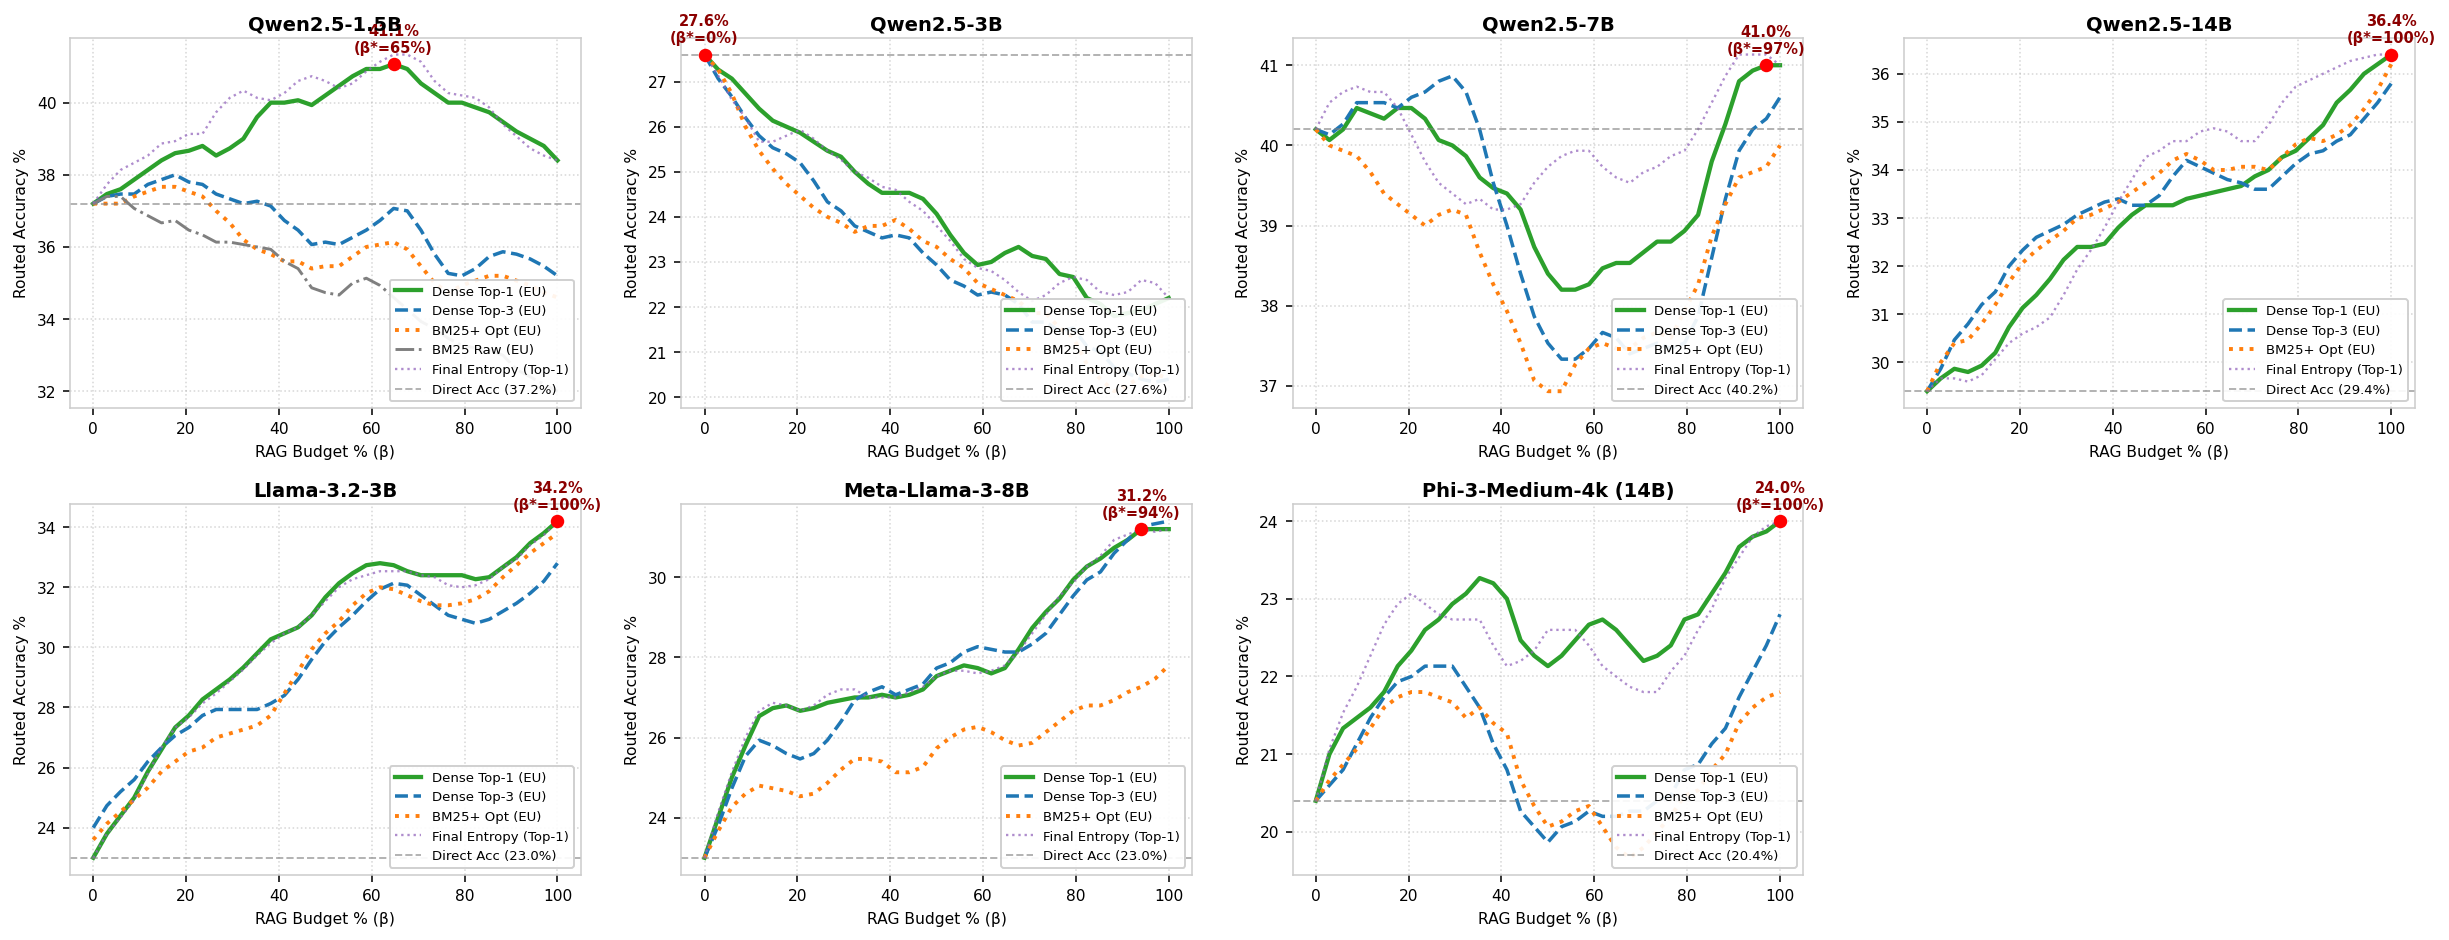

In [19]:
# Section 4: Multi-Panel Pareto RAG Routing Frontiers (Model Comparative Dashboard)
if 'dfs' not in locals() or not dfs:
    dfs = {r: load_rag_data(p) for r, p in available_runs.items()}
    dfs = {r: d for r, d in dfs.items() if len(d) > 0 and 'is_correct_direct' in d.columns and 'is_correct_rag' in d.columns}

# Ensure dfs contains strictly unique (Condition, Model) entries
cleaned_dfs = {}
seen_clean = set()
for r in sorted(dfs.keys(), key=lambda k: parse_run_tag(k)['sort_key']):
    m = parse_run_tag(r)
    k = (m['condition'], m['model_name'])
    if k not in seen_clean:
        seen_clean.add(k)
        cleaned_dfs[r] = dfs[r]
dfs = cleaned_dfs

# Group runs by model architecture (ordered by family & scale)
models_dict = {}
for m_name in sorted(dfs.keys(), key=lambda k: (parse_run_tag(k)['sort_key'][1], parse_run_tag(k)['sort_key'][2], parse_run_tag(k)['sort_key'][0])):
    df = dfs[m_name]
    if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns:
        continue
    meta = parse_run_tag(m_name)
    m_label = f"{meta['family']} - {meta['model_name']}"
    if m_label not in models_dict:
        models_dict[m_label] = {}
    models_dict[m_label][meta['cond_type']] = (m_name, df)

unique_models = list(models_dict.keys())
n_arch = len(unique_models)

if n_arch > 0:
    ncols = min(4, n_arch)
    nrows = int(np.ceil(n_arch / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.4 * nrows), squeeze=False)
    
    style_map = {
        'dense_top1': {'color': '#2ca02c', 'linestyle': '-', 'linewidth': 2.2, 'label': 'Dense Top-1 (EU)'},
        'dense':      {'color': '#1f77b4', 'linestyle': '--', 'linewidth': 1.8, 'label': 'Dense Top-3 (EU)'},
        'bm25_opt':   {'color': '#ff7f0e', 'linestyle': ':', 'linewidth': 2.0, 'label': 'BM25+ Opt (EU)'},
        'bm25_raw':   {'color': '#7f7f7f', 'linestyle': '-.', 'linewidth': 1.5, 'label': 'BM25 Raw (EU)'},
    }
    
    # Operational routing policies only (negative control distractor excluded from Pareto operational curves)
    operational_conditions = ['dense_top1', 'dense', 'bm25_opt', 'bm25_raw']
    
    for idx, m_label in enumerate(unique_models):
        r, c = divmod(idx, ncols)
        ax = axes[r, c]
        conds = models_dict[m_label]
        meta_sample = parse_run_tag(list(conds.values())[0][0])
        
        for cond_key in operational_conditions:
            if cond_key not in conds:
                continue
            m_name, df = conds[cond_key]
            if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns:
                continue
            yd = df['is_correct_direct'].values
            yr = df['is_correct_rag'].values
            
            b_grid, acc_eu = compute_pareto_curve(df['eu_pre'].values, yd, yr, n_points=35, smooth_window=3)
            cfg = style_map.get(cond_key, {'color': 'black', 'linestyle': '-', 'linewidth': 1.5, 'label': cond_key})
            
            ax.plot(b_grid * 100, acc_eu * 100, color=cfg['color'], linestyle=cfg['linestyle'],
                    linewidth=cfg['linewidth'], label=cfg['label'])
            
            # Mark peak operating point for primary condition
            if cond_key == 'dense_top1' or (cond_key == 'dense' and 'dense_top1' not in conds):
                opt_idx = np.argmax(acc_eu)
                ax.scatter([b_grid[opt_idx] * 100], [acc_eu[opt_idx] * 100], color='red', s=35, zorder=5)
                ax.annotate(f"{acc_eu[opt_idx]*100:.1f}%\n(β*={b_grid[opt_idx]*100:.0f}%)",
                            (b_grid[opt_idx] * 100, acc_eu[opt_idx] * 100),
                            textcoords="offset points", xytext=(0, 6), ha='center',
                            fontsize=7.5, fontweight='bold', color='darkred')
        
        # Final Entropy baseline for dense_top1 if available
        ref_cond = 'dense_top1' if 'dense_top1' in conds else list(conds.keys())[0]
        ref_df = conds[ref_cond][1]
        yd_ref = ref_df['is_correct_direct'].values
        yr_ref = ref_df['is_correct_rag'].values
        ent_col = 'h_final_pre' if 'h_final_pre' in ref_df.columns else ('eu_pre' if 'eu_pre' in ref_df.columns else None)
        if ent_col:
            b_grid, acc_ent = compute_pareto_curve(ref_df[ent_col].values, yd_ref, yr_ref, n_points=35, smooth_window=3)
            ax.plot(b_grid * 100, acc_ent * 100, color='#9467bd', linestyle=':', linewidth=1.2, alpha=0.75, label='Final Entropy (Top-1)')
        
        # Direct baseline horizontal line
        base_direct_acc = float(np.mean(yd_ref)) * 100
        ax.axhline(base_direct_acc, color='gray', linestyle='--', linewidth=1.0, alpha=0.6, label=f'Direct Acc ({base_direct_acc:.1f}%)')
        
        ax.set_title(f"{meta_sample['model_name']}", fontsize=10, fontweight='bold', pad=4)
        ax.set_xlabel("RAG Budget % (β)", fontsize=8)
        ax.set_ylabel("Routed Accuracy %", fontsize=8)
        ax.tick_params(labelsize=8)
        ax.legend(fontsize=6.8, loc='lower right', frameon=True, framealpha=0.92)
        ax.grid(True, linestyle=':', alpha=0.5)
        
    for idx in range(n_arch, nrows * ncols):
        r, c = divmod(idx, ncols)
        fig.delaxes(axes[r, c])
        
    plt.tight_layout()
    plt.show()


## 5. Consolidated Benchmark Summary & Budget-Constrained Efficiency

Comparative evaluation reporting baseline, full RAG, and selective routing metrics across clean condition chunks across all evaluated models, with the BM25 Raw baseline at the end:
- **`Acc @ 25% Budget` & `Gain @ 25%`**: Accuracy achieved when retrieval is triggered for only 25% of queries (saving 75% of retrieval and LLM context calls), and improvement over Direct generation.
- **`Acc @ 50% Budget` & `Gain @ 50%`**: Balanced compute operating point.
- **`Peak Routed Acc` & `Optimal Budget β*`**: Empirical apex of the Pareto curve.
- **`Selective Routing Gain`**: Accuracy lift of peak selective routing over Full (100%) RAG.


In [20]:
# Section 5: Consolidated Benchmark Summary Table with Fixed-Budget Metrics
if 'dfs' not in locals() or not dfs:
    dfs = {r: load_rag_data(p) for r, p in available_runs.items()}
    dfs = {r: d for r, d in dfs.items() if len(d) > 0 and 'is_correct_direct' in d.columns and 'is_correct_rag' in d.columns}

summary_records = []
seen_summary = set()

sorted_runs = sorted(dfs.keys(), key=lambda k: parse_run_tag(k)['sort_key'])

for m_name in sorted_runs:
    df = dfs[m_name]
    if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns:
        continue
    meta = parse_run_tag(m_name)
    model_key = (meta['condition'], meta['model_name'])
    if model_key in seen_summary:
        continue
    seen_summary.add(model_key)
    
    yd = df['is_correct_direct'].values
    yr = df['is_correct_rag'].values
    base_acc = float(np.mean(yd))
    rag_acc = float(np.mean(yr))
    net_rag_delta = rag_acc - base_acc
    
    eu_col = 'eu_pre' if 'eu_pre' in df.columns else None
    if eu_col is not None:
        b_grid, acc_eu = compute_pareto_curve(df[eu_col].values, yd, yr, n_points=35, smooth_window=3)
    else:
        b_grid = np.linspace(0.0, 1.0, 35)
        acc_eu = (1.0 - b_grid) * base_acc + b_grid * rag_acc
    
    # Fixed budget operating points
    acc_25 = float(np.interp(0.25, b_grid, acc_eu))
    acc_50 = float(np.interp(0.50, b_grid, acc_eu))
    gain_25 = acc_25 - base_acc
    gain_50 = acc_50 - base_acc
    
    opt_idx = np.argmax(acc_eu)
    peak_acc_eu = float(acc_eu[opt_idx])
    opt_budget_eu = float(b_grid[opt_idx]) * 100
    routing_lift = peak_acc_eu - rag_acc
    
    hit_rate_str = f"{df['retriever_hit_at_k'].mean() * 100:.1f}%" if 'retriever_hit_at_k' in df.columns else "N/A"
    mean_deu = f"{df['delta_eu'].mean():+.4f}" if 'delta_eu' in df.columns else "N/A"
    
    summary_records.append({
        'Condition': meta['condition'],
        'Family': meta['family'],
        'Model': meta['model_name'],
        'Hit@K': hit_rate_str,
        'Direct Acc': f"{base_acc * 100:.2f}%",
        'Full RAG Acc': f"{rag_acc * 100:.2f}%",
        'Net RAG Δ': f"{net_rag_delta * 100:+.2f}%",
        'Acc @ 25% Budget': f"{acc_25 * 100:.2f}% ({gain_25 * 100:+.2f}%)",
        'Acc @ 50% Budget': f"{acc_50 * 100:.2f}% ({gain_50 * 100:+.2f}%)",
        'Peak Routed Acc (EU)': f"{peak_acc_eu * 100:.2f}% (β*={opt_budget_eu:.0f}%)",
        'Selective Routing Gain': f"{routing_lift * 100:+.2f}%",
        'Mean ΔEU': mean_deu
    })

summary_table = pd.DataFrame(summary_records)
display_table_chunks(summary_table, title="Consolidated Fixed-Budget Benchmark Efficiency")


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Net RAG Δ,Acc @ 25% Budget,Acc @ 50% Budget,Peak Routed Acc (EU),Selective Routing Gain,Mean ΔEU
0,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-1.5B,100.0%,37.20%,45.80%,+8.60%,39.97% (+2.77%),43.20% (+6.00%),46.53% (β*=74%),+0.73%,+0.0680
1,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-3B,100.0%,27.40%,24.40%,-3.00%,24.63% (-2.77%),23.80% (-3.60%),27.40% (β*=0%),+3.00%,+0.0851
2,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-7B,100.0%,40.20%,46.00%,+5.80%,41.17% (+0.97%),40.47% (+0.27%),46.00% (β*=100%),+0.00%,+0.0451
3,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-14B,100.0%,29.40%,39.00%,+9.60%,33.03% (+3.63%),35.00% (+5.60%),39.00% (β*=100%),+0.00%,+0.0213
4,Oracle (Gold Fact),Llama,Llama-3.2-3B,100.0%,23.40%,37.40%,+14.00%,29.33% (+5.93%),33.87% (+10.47%),37.40% (β*=100%),+0.00%,+0.1387
5,Oracle (Gold Fact),Llama,Meta-Llama-3-8B,100.0%,23.00%,36.20%,+13.20%,28.40% (+5.40%),30.53% (+7.53%),36.20% (β*=100%),+0.00%,+0.0568
6,Oracle (Gold Fact),Phi-3,Phi-3-Medium-4k (14B),100.0%,20.40%,24.40%,+4.00%,23.17% (+2.77%),22.40% (+2.00%),24.40% (β*=100%),+0.00%,+0.1002


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Net RAG Δ,Acc @ 25% Budget,Acc @ 50% Budget,Peak Routed Acc (EU),Selective Routing Gain,Mean ΔEU
7,Dense (Top-1),Qwen 2.5,Qwen2.5-1.5B,52.0%,37.20%,38.40%,+1.20%,38.67% (+1.47%),40.20% (+3.00%),41.07% (β*=65%),+2.67%,+0.0331
8,Dense (Top-1),Qwen 2.5,Qwen2.5-3B,52.0%,27.60%,22.20%,-5.40%,25.57% (-2.03%),24.07% (-3.53%),27.60% (β*=0%),+5.40%,+0.0777
9,Dense (Top-1),Qwen 2.5,Qwen2.5-7B,52.0%,40.20%,41.00%,+0.80%,40.20% (+0.00%),38.40% (-1.80%),41.00% (β*=97%),+0.00%,+0.0570
10,Dense (Top-1),Qwen 2.5,Qwen2.5-14B,52.0%,29.40%,36.40%,+7.00%,31.57% (+2.17%),33.27% (+3.87%),36.40% (β*=100%),+0.00%,-0.0018
11,Dense (Top-1),Llama,Llama-3.2-3B,52.0%,23.00%,34.20%,+11.20%,28.43% (+5.43%),31.67% (+8.67%),34.20% (β*=100%),+0.00%,+0.1258
12,Dense (Top-1),Llama,Meta-Llama-3-8B,52.0%,23.00%,31.20%,+8.20%,26.80% (+3.80%),27.53% (+4.53%),31.20% (β*=94%),+0.00%,+0.0516
13,Dense (Top-1),Phi-3,Phi-3-Medium-4k (14B),52.0%,20.40%,24.00%,+3.60%,22.67% (+2.27%),22.13% (+1.73%),24.00% (β*=100%),+0.00%,+0.0702


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Net RAG Δ,Acc @ 25% Budget,Acc @ 50% Budget,Peak Routed Acc (EU),Selective Routing Gain,Mean ΔEU
14,Dense (Top-3),Qwen 2.5,Qwen2.5-1.5B,71.8%,37.20%,35.20%,-2.00%,37.60% (+0.40%),36.13% (-1.07%),38.00% (β*=18%),+2.80%,+0.0042
15,Dense (Top-3),Qwen 2.5,Qwen2.5-3B,71.8%,27.60%,20.40%,-7.20%,24.57% (-3.03%),22.93% (-4.67%),27.60% (β*=0%),+7.20%,+0.0586
16,Dense (Top-3),Qwen 2.5,Qwen2.5-7B,71.8%,40.20%,40.60%,+0.40%,40.73% (+0.53%),37.53% (-2.67%),40.87% (β*=29%),+0.27%,+0.0496
17,Dense (Top-3),Qwen 2.5,Qwen2.5-14B,71.8%,29.40%,35.80%,+6.40%,32.67% (+3.27%),33.47% (+4.07%),35.80% (β*=100%),+0.00%,+0.0205
18,Dense (Top-3),Llama,Llama-3.2-3B,71.8%,24.00%,32.80%,+8.80%,27.83% (+3.83%),30.20% (+6.20%),32.80% (β*=100%),+0.00%,+0.0788
19,Dense (Top-3),Llama,Meta-Llama-3-8B,71.8%,23.00%,31.40%,+8.40%,25.77% (+2.77%),27.73% (+4.73%),31.40% (β*=100%),+0.00%,+0.0212
20,Dense (Top-3),Phi-3,Phi-3-Medium-4k (14B),71.8%,20.40%,22.80%,+2.40%,22.13% (+1.73%),19.87% (-0.53%),22.80% (β*=100%),+0.00%,+0.0969


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Net RAG Δ,Acc @ 25% Budget,Acc @ 50% Budget,Peak Routed Acc (EU),Selective Routing Gain,Mean ΔEU
21,BM25+ (Top-3),Qwen 2.5,Qwen2.5-1.5B,57.4%,37.20%,34.60%,-2.60%,37.20% (+0.00%),35.47% (-1.73%),37.67% (β*=15%),+3.07%,-0.0346
22,BM25+ (Top-3),Qwen 2.5,Qwen2.5-3B,57.4%,27.60%,20.40%,-7.20%,24.10% (-3.50%),23.33% (-4.27%),27.60% (β*=0%),+7.20%,+0.0595
23,BM25+ (Top-3),Qwen 2.5,Qwen2.5-7B,57.4%,40.20%,40.00%,-0.20%,39.07% (-1.13%),36.93% (-3.27%),40.20% (β*=0%),+0.20%,+0.0528
24,BM25+ (Top-3),Qwen 2.5,Qwen2.5-14B,57.4%,29.40%,36.20%,+6.80%,32.43% (+3.03%),33.93% (+4.53%),36.20% (β*=100%),+0.00%,+0.0045
25,BM25+ (Top-3),Llama,Llama-3.2-3B,57.4%,23.60%,33.80%,+10.20%,26.83% (+3.23%),30.47% (+6.87%),33.80% (β*=100%),+0.00%,+0.0657
26,BM25+ (Top-3),Llama,Meta-Llama-3-8B,57.4%,23.00%,27.80%,+4.80%,24.73% (+1.73%),25.73% (+2.73%),27.80% (β*=100%),+0.00%,+0.0103
27,BM25+ (Top-3),Phi-3,Phi-3-Medium-4k (14B),57.4%,20.40%,21.80%,+1.40%,21.77% (+1.37%),20.07% (-0.33%),21.80% (β*=21%),+0.00%,+0.0718


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Net RAG Δ,Acc @ 25% Budget,Acc @ 50% Budget,Peak Routed Acc (EU),Selective Routing Gain,Mean ΔEU
28,BM25 Raw (Top-3),Qwen 2.5,Qwen2.5-1.5B,39.0%,37.20%,32.00%,-5.20%,36.23% (-0.97%),34.73% (-2.47%),37.40% (β*=3%),+5.40%,-0.0433


## 6. Stratified Retrieval Diagnostics, Epistemic Derivatives & Targeted Ablations

### Core Diagnostic Metrics
1. **Deficit Recovery Rate (0 $\rightarrow$ 1)**: Proportion of initially incorrect direct answers corrected by RAG: $\frac{N_{0 \rightarrow 1}}{N_0}$.
2. **Distraction Rate (1 $\rightarrow$ 0)**: Proportion of initially correct direct answers corrupted by misleading distractor context: $\frac{N_{1 \rightarrow 0}}{N_1}$.
3. **Epistemic Grounding Contrast ($\Gamma_{\mathrm{EU}}$)**: Contrast between uncertainty dissipation on successful recoveries vs. unsuccessful distractions:
   $$\Gamma_{\mathrm{EU}} = \mu(\Delta \mathrm{EU}_{0 \rightarrow 1}) - \mu(\Delta \mathrm{EU}_{1 \rightarrow 0})$$
4. **Distraction Shielding Rate ($\mathrm{DSR}$)**: Percentage of potential distraction errors averted by selectively routing at optimal budget $\beta^*$.
5. **Routed Recovery/Distraction Ratio**: Ratio of recovered answers to distraction errors admitted into the routed response pool.


In [21]:
# Section 6: Stratified Retrieval Diagnostics & Dedicated Ablation Tables
if 'dfs' not in locals() or not dfs:
    dfs = {r: load_rag_data(p) for r, p in available_runs.items()}
    dfs = {r: d for r, d in dfs.items() if len(d) > 0 and 'is_correct_direct' in d.columns and 'is_correct_rag' in d.columns}

# Ensure dfs contains strictly unique (Condition, Model) entries
cleaned_dfs = {}
seen_clean = set()
for r in sorted(dfs.keys(), key=lambda k: parse_run_tag(k)['sort_key']):
    m = parse_run_tag(r)
    k = (m['condition'], m['model_name'])
    if k not in seen_clean:
        seen_clean.add(k)
        cleaned_dfs[r] = dfs[r]
dfs = cleaned_dfs

stratified_records = []
seen_stratified = set()

sorted_runs = sorted(dfs.keys(), key=lambda k: parse_run_tag(k)['sort_key'])

for m_name in sorted_runs:
    df = dfs[m_name]
    if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns or 'retriever_hit_at_k' not in df.columns:
        continue
        
    meta = parse_run_tag(m_name)
    model_key = (meta['condition'], meta['model_name'])
    if model_key in seen_stratified:
        continue
    seen_stratified.add(model_key)
    
    n_total = len(df)
    yd = df['is_correct_direct'].values
    yr = df['is_correct_rag'].values
    eu = df['eu_pre'].values if 'eu_pre' in df.columns else np.zeros(n_total)
    delta_eu = df['delta_eu'].values if 'delta_eu' in df.columns else np.zeros(n_total)
    
    rec_mask = (yd == 0) & (yr == 1)
    dis_mask = (yd == 1) & (yr == 0)
    
    rec_count = int(np.sum(rec_mask))
    dis_count = int(np.sum(dis_mask))
    init_wrong = int(np.sum(yd == 0))
    init_right = int(np.sum(yd == 1))
    
    rec_rate = (rec_count / init_wrong * 100) if init_wrong > 0 else 0.0
    dis_rate = (dis_count / init_right * 100) if init_right > 0 else 0.0
    
    eu_rec = float(np.mean(delta_eu[rec_mask])) if rec_count > 0 else 0.0
    eu_dis = float(np.mean(delta_eu[dis_mask])) if dis_count > 0 else 0.0
    gamma_eu = eu_rec - eu_dis
    
    # Optimal Pareto EU Routing Derivatives
    sorted_idx = np.argsort(-eu)
    budgets = np.linspace(0.0, 1.0, 35)
    best_b, best_acc, best_k = 0.0, -1.0, 0
    for b in budgets:
        k = int(round(b * n_total))
        routed = np.copy(yd)
        if k > 0:
            routed[sorted_idx[:k]] = yr[sorted_idx[:k]]
        acc = float(np.mean(routed))
        if acc > best_acc:
            best_acc = acc
            best_b = b
            best_k = k
            
    routed_set = set(sorted_idx[:best_k])
    rec_routed = int(sum(1 for i in np.where(rec_mask)[0] if i in routed_set))
    dis_routed = int(sum(1 for i in np.where(dis_mask)[0] if i in routed_set))
    
    dis_shielded_pct = ((dis_count - dis_routed) / max(1, dis_count)) * 100
    routed_advantage = (rec_routed / max(1, dis_routed)) if dis_routed > 0 else (float(rec_routed) if rec_routed > 0 else 0.0)
    
    hit_k_rate = df['retriever_hit_at_k'].mean() * 100
    
    stratified_records.append({
        'Condition': meta['condition'],
        'Family': meta['family'],
        'Model': meta['model_name'],
        'Hit@K': f"{hit_k_rate:.1f}%",
        'Direct Acc': f"{np.mean(yd)*100:.2f}%",
        'Full RAG Acc': f"{np.mean(yr)*100:.2f}%",
        'Deficit Recovery Rate': f"{rec_rate:.1f}% ({rec_count}/{init_wrong})",
        'Distraction Rate': f"{dis_rate:.1f}% ({dis_count}/{init_right})",
        'ΔEU on Rec': f"{eu_rec:+.4f}",
        'ΔEU on Dis': f"{eu_dis:+.4f}",
        'Epistemic Contrast Γ_EU': f"{gamma_eu:+.4f}",
        'Shielded @ β*': f"{dis_shielded_pct:.1f}% ({dis_count - dis_routed}/{dis_count})",
        'Routed Rec/Dis Ratio': f"{routed_advantage:.2f}x ({rec_routed}:{dis_routed})"
    })

master_diagnostic_df = pd.DataFrame(stratified_records)
print("=== MASTER STRATIFIED RETRIEVAL DIAGNOSTICS ===")
display_table_chunks(master_diagnostic_df)

# Group runs by model architecture for ablation tables
models_dict = {}
for m_name in sorted(dfs.keys(), key=lambda k: (parse_run_tag(k)['sort_key'][1], parse_run_tag(k)['sort_key'][2], parse_run_tag(k)['sort_key'][0])):
    df = dfs[m_name]
    if 'is_correct_direct' not in df.columns or 'is_correct_rag' not in df.columns:
        continue
    meta = parse_run_tag(m_name)
    m_label = f"{meta['family']} - {meta['model_name']}"
    if m_label not in models_dict:
        models_dict[m_label] = {}
    models_dict[m_label][meta['cond_type']] = (m_name, df)

# -----------------------------------------------------------------------------------
# Dedicated Table A: Context Density Ablation (Dense Top-1 vs. Dense Top-3)
# -----------------------------------------------------------------------------------
density_records = []
for m_label, conds in models_dict.items():
    if 'dense_top1' in conds and 'dense' in conds:
        _, df_top1 = conds['dense_top1']
        _, df_top3 = conds['dense']
        meta = parse_run_tag(conds['dense_top1'][0])
        
        if 'is_correct_direct' not in df_top1.columns or 'is_correct_rag' not in df_top1.columns:
            continue
        if 'is_correct_direct' not in df_top3.columns or 'is_correct_rag' not in df_top3.columns:
            continue
            
        yd_top1 = df_top1['is_correct_direct'].values
        yr_top1 = df_top1['is_correct_rag'].values
        yd_top3 = df_top3['is_correct_direct'].values
        yr_top3 = df_top3['is_correct_rag'].values
        
        d_acc = np.mean(yd_top1) * 100
        top1_rag = np.mean(yr_top1) * 100
        top3_rag = np.mean(yr_top3) * 100
        
        dis_top1 = np.sum((yd_top1 == 1) & (yr_top1 == 0)) / max(1, np.sum(yd_top1 == 1)) * 100
        dis_top3 = np.sum((yd_top3 == 1) & (yr_top3 == 0)) / max(1, np.sum(yd_top3 == 1)) * 100
        
        b_grid, acc_top1_eu = compute_pareto_curve(df_top1['eu_pre'].values, yd_top1, yr_top1, n_points=35, smooth_window=3)
        peak_top1 = np.max(acc_top1_eu) * 100
        
        density_records.append({
            'Model': meta['model_name'],
            'Direct Acc': f"{d_acc:.2f}%",
            'Top-3 Full RAG': f"{top3_rag:.2f}%",
            'Top-1 Full RAG': f"{top1_rag:.2f}%",
            'Density Gain (Top-1 - Top-3)': f"{top1_rag - top3_rag:+.2f}%",
            'Top-3 Distraction Rate': f"{dis_top3:.1f}%",
            'Top-1 Distraction Rate': f"{dis_top1:.1f}%",
            'Distraction Reduction': f"{dis_top3 - dis_top1:+.1f}%",
            'Top-1 Peak Routed Acc': f"{peak_top1:.2f}%"
        })

if density_records:
    print("\n=== TABLE A: CONTEXT DENSITY ABLATION (TOP-1 VS TOP-3 SUPPRESSION) ===")
    display(pd.DataFrame(density_records))

# -----------------------------------------------------------------------------------
# Dedicated Table B: Retrieval Modality Ablation (Dense Top-3 vs. BM25+ Top-3)
# -----------------------------------------------------------------------------------
modality_records = []
for m_label, conds in models_dict.items():
    if 'dense' in conds and 'bm25_opt' in conds:
        _, df_dense = conds['dense']
        _, df_bm25 = conds['bm25_opt']
        meta = parse_run_tag(conds['dense'][0])
        
        if 'is_correct_direct' not in df_dense.columns or 'is_correct_rag' not in df_dense.columns:
            continue
        if 'is_correct_direct' not in df_bm25.columns or 'is_correct_rag' not in df_bm25.columns:
            continue
            
        hit_dense = df_dense['retriever_hit_at_k'].mean() * 100
        hit_bm25 = df_bm25['retriever_hit_at_k'].mean() * 100
        
        acc_dense = df_dense['is_correct_rag'].mean() * 100
        acc_bm25 = df_bm25['is_correct_rag'].mean() * 100
        
        # Deficit recovery rates
        rec_dense = np.sum((df_dense['is_correct_direct'] == 0) & (df_dense['is_correct_rag'] == 1)) / max(1, np.sum(df_dense['is_correct_direct'] == 0)) * 100
        rec_bm25 = np.sum((df_bm25['is_correct_direct'] == 0) & (df_bm25['is_correct_rag'] == 1)) / max(1, np.sum(df_bm25['is_correct_direct'] == 0)) * 100
        
        modality_records.append({
            'Model': meta['model_name'],
            'Dense Hit@3': f"{hit_dense:.1f}%",
            'BM25+ Hit@3': f"{hit_bm25:.1f}%",
            'Dense RAG Acc': f"{acc_dense:.2f}%",
            'BM25+ RAG Acc': f"{acc_bm25:.2f}%",
            'Dense Recovery Rate': f"{rec_dense:.1f}%",
            'BM25+ Recovery Rate': f"{rec_bm25:.1f}%"
        })

if modality_records:
    print("\n=== TABLE B: RETRIEVAL MODALITY ABLATION (DENSE VS BM25+ LEXICAL) ===")
    display(pd.DataFrame(modality_records))

# -----------------------------------------------------------------------------------
# Dedicated Table C: Negative Control Ablation (Dense Top-1 vs. Distractor Noise)
# -----------------------------------------------------------------------------------
noise_records = []
for m_label, conds in models_dict.items():
    if 'dense_top1' in conds and 'distractor' in conds:
        _, df_top1 = conds['dense_top1']
        _, df_dis = conds['distractor']
        meta = parse_run_tag(conds['dense_top1'][0])
        
        if 'is_correct_direct' not in df_top1.columns or 'is_correct_rag' not in df_top1.columns:
            continue
        if 'is_correct_direct' not in df_dis.columns or 'is_correct_rag' not in df_dis.columns:
            continue
            
        top1_rag = np.mean(df_top1['is_correct_rag'].values) * 100
        dis_rag = np.mean(df_dis['is_correct_rag'].values) * 100
        
        yd_dis = df_dis['is_correct_direct'].values
        yr_dis = df_dis['is_correct_rag'].values
        dis_distraction = np.sum((yd_dis == 1) & (yr_dis == 0)) / max(1, np.sum(yd_dis == 1)) * 100
        
        mean_deu_dis = df_dis['delta_eu'].mean() if 'delta_eu' in df_dis.columns else 0.0
        
        noise_records.append({
            'Model': meta['model_name'],
            'Dense Top-1 Acc': f"{top1_rag:.2f}%",
            'Distractor RAG Acc': f"{dis_rag:.2f}%",
            'Noise Degradation': f"{dis_rag - top1_rag:+.2f}%",
            'Distraction Rate (Noise)': f"{dis_distraction:.1f}%",
            'Mean ΔEU (Noise)': f"{mean_deu_dis:+.4f}"
        })

if noise_records:
    print("\n=== TABLE C: NEGATIVE CONTROL ABLATION (DENSE TOP-1 VS DISTRACTOR NOISE) ===")
    display(pd.DataFrame(noise_records))


=== MASTER STRATIFIED RETRIEVAL DIAGNOSTICS ===


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Deficit Recovery Rate,Distraction Rate,ΔEU on Rec,ΔEU on Dis,Epistemic Contrast Γ_EU,Shielded @ β*,Routed Rec/Dis Ratio
0,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-1.5B,100.0%,37.20%,45.80%,34.4% (108/314),34.9% (65/186),+0.1580,-0.0441,+0.2021,33.8% (22/65),2.14x (92:43)
1,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-3B,100.0%,27.40%,24.40%,16.3% (59/363),54.0% (74/137),+0.0852,+0.0918,-0.0066,100.0% (74/74),0.00x (0:0)
2,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-7B,100.0%,40.20%,46.00%,28.4% (85/299),27.9% (56/201),+0.0377,+0.0170,+0.0207,0.0% (0/56),1.52x (85:56)
3,Oracle (Gold Fact),Qwen 2.5,Qwen2.5-14B,100.0%,29.40%,39.00%,21.2% (75/353),18.4% (27/147),+0.0304,+0.0078,+0.0226,0.0% (0/27),2.78x (75:27)
4,Oracle (Gold Fact),Llama,Llama-3.2-3B,100.0%,23.40%,37.40%,25.3% (97/383),23.1% (27/117),+0.2022,+0.0533,+0.1489,0.0% (0/27),3.59x (97:27)
5,Oracle (Gold Fact),Llama,Meta-Llama-3-8B,100.0%,23.00%,36.20%,24.4% (94/385),24.3% (28/115),+0.1237,-0.0254,+0.1491,3.6% (1/28),3.44x (93:27)
6,Oracle (Gold Fact),Phi-3,Phi-3-Medium-4k (14B),100.0%,20.40%,24.40%,16.8% (67/398),46.1% (47/102),+0.1235,+0.0573,+0.0662,0.0% (0/47),1.43x (67:47)


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Deficit Recovery Rate,Distraction Rate,ΔEU on Rec,ΔEU on Dis,Epistemic Contrast Γ_EU,Shielded @ β*,Routed Rec/Dis Ratio
7,Dense (Top-1),Qwen 2.5,Qwen2.5-1.5B,52.0%,37.20%,38.40%,25.2% (79/314),39.2% (73/186),+0.1085,-0.0460,+0.1544,38.4% (28/73),1.44x (65:45)
8,Dense (Top-1),Qwen 2.5,Qwen2.5-3B,52.0%,27.60%,22.20%,14.1% (51/362),56.5% (78/138),+0.0952,+0.0674,+0.0278,100.0% (78/78),0.00x (0:0)
9,Dense (Top-1),Qwen 2.5,Qwen2.5-7B,52.0%,40.20%,41.00%,22.4% (67/299),31.3% (63/201),+0.0737,+0.0273,+0.0464,1.6% (1/63),1.06x (66:62)
10,Dense (Top-1),Qwen 2.5,Qwen2.5-14B,52.0%,29.40%,36.40%,19.0% (67/353),21.8% (32/147),+0.0272,-0.0664,+0.0936,0.0% (0/32),2.09x (67:32)
11,Dense (Top-1),Llama,Llama-3.2-3B,52.0%,23.00%,34.20%,21.8% (84/385),24.3% (28/115),+0.2347,+0.0566,+0.1781,0.0% (0/28),3.00x (84:28)
12,Dense (Top-1),Llama,Meta-Llama-3-8B,52.0%,23.00%,31.20%,19.2% (74/385),28.7% (33/115),+0.1531,-0.0476,+0.2007,3.0% (1/33),2.31x (74:32)
13,Dense (Top-1),Phi-3,Phi-3-Medium-4k (14B),52.0%,20.40%,24.00%,15.8% (63/398),44.1% (45/102),+0.0904,+0.0380,+0.0524,0.0% (0/45),1.40x (63:45)


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Deficit Recovery Rate,Distraction Rate,ΔEU on Rec,ΔEU on Dis,Epistemic Contrast Γ_EU,Shielded @ β*,Routed Rec/Dis Ratio
14,Dense (Top-3),Qwen 2.5,Qwen2.5-1.5B,71.8%,37.20%,35.20%,23.6% (74/314),45.2% (84/186),+0.0240,-0.0608,+0.0847,86.9% (73/84),1.45x (16:11)
15,Dense (Top-3),Qwen 2.5,Qwen2.5-3B,71.8%,27.60%,20.40%,13.3% (48/362),60.9% (84/138),+0.0801,+0.0209,+0.0591,100.0% (84/84),0.00x (0:0)
16,Dense (Top-3),Qwen 2.5,Qwen2.5-7B,71.8%,40.20%,40.60%,25.1% (75/299),36.3% (73/201),+0.0426,-0.0299,+0.0725,71.2% (52/73),1.19x (25:21)
17,Dense (Top-3),Qwen 2.5,Qwen2.5-14B,71.8%,29.40%,35.80%,20.7% (73/353),27.9% (41/147),+0.0658,-0.0093,+0.0751,0.0% (0/41),1.78x (73:41)
18,Dense (Top-3),Llama,Llama-3.2-3B,71.8%,24.00%,32.80%,21.1% (80/380),30.0% (36/120),+0.1656,+0.0585,+0.1071,0.0% (0/36),2.22x (80:36)
19,Dense (Top-3),Llama,Meta-Llama-3-8B,71.8%,23.00%,31.40%,21.6% (83/385),35.7% (41/115),+0.0985,-0.0493,+0.1478,2.4% (1/41),2.05x (82:40)
20,Dense (Top-3),Phi-3,Phi-3-Medium-4k (14B),71.8%,20.40%,22.80%,14.8% (59/398),46.1% (47/102),+0.0900,+0.0578,+0.0322,0.0% (0/47),1.26x (59:47)


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Deficit Recovery Rate,Distraction Rate,ΔEU on Rec,ΔEU on Dis,Epistemic Contrast Γ_EU,Shielded @ β*,Routed Rec/Dis Ratio
21,BM25+ (Top-3),Qwen 2.5,Qwen2.5-1.5B,57.4%,37.20%,34.60%,22.6% (71/314),45.2% (84/186),+0.0253,-0.1417,+0.1670,88.1% (74/84),1.30x (13:10)
22,BM25+ (Top-3),Qwen 2.5,Qwen2.5-3B,57.4%,27.60%,20.40%,14.9% (54/362),65.2% (90/138),+0.1442,+0.0669,+0.0774,100.0% (90/90),0.00x (0:0)
23,BM25+ (Top-3),Qwen 2.5,Qwen2.5-7B,57.4%,40.20%,40.00%,24.4% (73/299),36.8% (74/201),+0.0507,+0.0230,+0.0277,100.0% (74/74),0.00x (0:0)
24,BM25+ (Top-3),Qwen 2.5,Qwen2.5-14B,57.4%,29.40%,36.20%,20.1% (71/353),25.2% (37/147),+0.0810,-0.0928,+0.1738,0.0% (0/37),1.92x (71:37)
25,BM25+ (Top-3),Llama,Llama-3.2-3B,57.4%,23.60%,33.80%,21.5% (82/382),26.3% (31/118),+0.1723,-0.0134,+0.1857,0.0% (0/31),2.65x (82:31)
26,BM25+ (Top-3),Llama,Meta-Llama-3-8B,57.4%,23.00%,27.80%,16.6% (64/385),34.8% (40/115),+0.0262,-0.1042,+0.1304,0.0% (0/40),1.60x (64:40)
27,BM25+ (Top-3),Phi-3,Phi-3-Medium-4k (14B),57.4%,20.40%,21.80%,13.1% (52/398),44.1% (45/102),+0.0559,-0.0330,+0.0888,73.3% (33/45),1.67x (20:12)


,Condition,Family,Model,Hit@K,Direct Acc,Full RAG Acc,Deficit Recovery Rate,Distraction Rate,ΔEU on Rec,ΔEU on Dis,Epistemic Contrast Γ_EU,Shielded @ β*,Routed Rec/Dis Ratio
28,BM25 Raw (Top-3),Qwen 2.5,Qwen2.5-1.5B,39.0%,37.20%,32.00%,19.4% (61/314),46.8% (87/186),-0.0009,-0.1238,+0.1229,98.9% (86/87),3.00x (3:1)



=== TABLE A: CONTEXT DENSITY ABLATION (TOP-1 VS TOP-3 SUPPRESSION) ===


,Model,Direct Acc,Top-3 Full RAG,Top-1 Full RAG,Density Gain (Top-1 - Top-3),Top-3 Distraction Rate,Top-1 Distraction Rate,Distraction Reduction,Top-1 Peak Routed Acc
0,Qwen2.5-1.5B,37.20%,35.20%,38.40%,+3.20%,45.2%,39.2%,+5.9%,41.07%
1,Qwen2.5-3B,27.60%,20.40%,22.20%,+1.80%,60.9%,56.5%,+4.3%,27.60%
2,Qwen2.5-7B,40.20%,40.60%,41.00%,+0.40%,36.3%,31.3%,+5.0%,41.00%
3,Qwen2.5-14B,29.40%,35.80%,36.40%,+0.60%,27.9%,21.8%,+6.1%,36.40%
4,Llama-3.2-3B,23.00%,32.80%,34.20%,+1.40%,30.0%,24.3%,+5.7%,34.20%
5,Meta-Llama-3-8B,23.00%,31.40%,31.20%,-0.20%,35.7%,28.7%,+7.0%,31.20%
6,Phi-3-Medium-4k (14B),20.40%,22.80%,24.00%,+1.20%,46.1%,44.1%,+2.0%,24.00%



=== TABLE B: RETRIEVAL MODALITY ABLATION (DENSE VS BM25+ LEXICAL) ===


,Model,Dense Hit@3,BM25+ Hit@3,Dense RAG Acc,BM25+ RAG Acc,Dense Recovery Rate,BM25+ Recovery Rate
0,Qwen2.5-1.5B,71.8%,57.4%,35.20%,34.60%,23.6%,22.6%
1,Qwen2.5-3B,71.8%,57.4%,20.40%,20.40%,13.3%,14.9%
2,Qwen2.5-7B,71.8%,57.4%,40.60%,40.00%,25.1%,24.4%
3,Qwen2.5-14B,71.8%,57.4%,35.80%,36.20%,20.7%,20.1%
4,Llama-3.2-3B,71.8%,57.4%,32.80%,33.80%,21.1%,21.5%
5,Meta-Llama-3-8B,71.8%,57.4%,31.40%,27.80%,21.6%,16.6%
6,Phi-3-Medium-4k (14B),71.8%,57.4%,22.80%,21.80%,14.8%,13.1%
